In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.metrics import r2_score, mean_absolute_percentage_error


In [3]:
df = pd.read_excel("train_predictions.xlsx", index_col=0) #index_col=0 serve para deixar int o dado

display(df)

,PRED,PRED_2,PRED_3,PRED_4,TRUE
2023-07-03,8.201683,8.352525,8.342525,5.201683,8.342525
2023-07-04,10.985485,11.460578,13.460578,7.985485,11.460578
2023-07-05,10.983031,11.232806,11.242806,7.983031,11.242806
2023-07-06,8.819176,8.943479,6.943479,5.819176,8.943479
2023-07-07,8.064021,7.222307,6.212307,5.064021,7.212307
...,...,...,...,...,...
2026-06-26,7.388175,6.657052,4.667052,4.388175,6.667052
2026-06-27,7.807723,6.748333,5.758333,4.807723,6.758333
2026-06-28,8.621619,8.646798,9.636798,5.621619,8.636798
2026-06-29,8.455132,7.892713,5.902713,5.455132,7.902713


In [4]:
# Checagem dos dados: 

df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1094 entries, 2023-07-03 to 2026-06-30
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   PRED    1092 non-null   float64
 1   PRED_2  1092 non-null   float64
 2   PRED_3  1092 non-null   float64
 3   PRED_4  1092 non-null   float64
 4   TRUE    1092 non-null   float64
dtypes: float64(5)
memory usage: 51.3 KB


PRED      2
PRED_2    2
PRED_3    2
PRED_4    2
TRUE      2
dtype: int64

In [5]:
df = df.dropna() # excluir valores ausentes 
df.isna().sum()

PRED      0
PRED_2    0
PRED_3    0
PRED_4    0
TRUE      0
dtype: int64

# AVALIAÇÃO DO MODELO:

## PRED

In [6]:
df_treino = df[["PRED", "TRUE"]]

# Correto
df_treino.columns = ["PRED", "TRUE"]

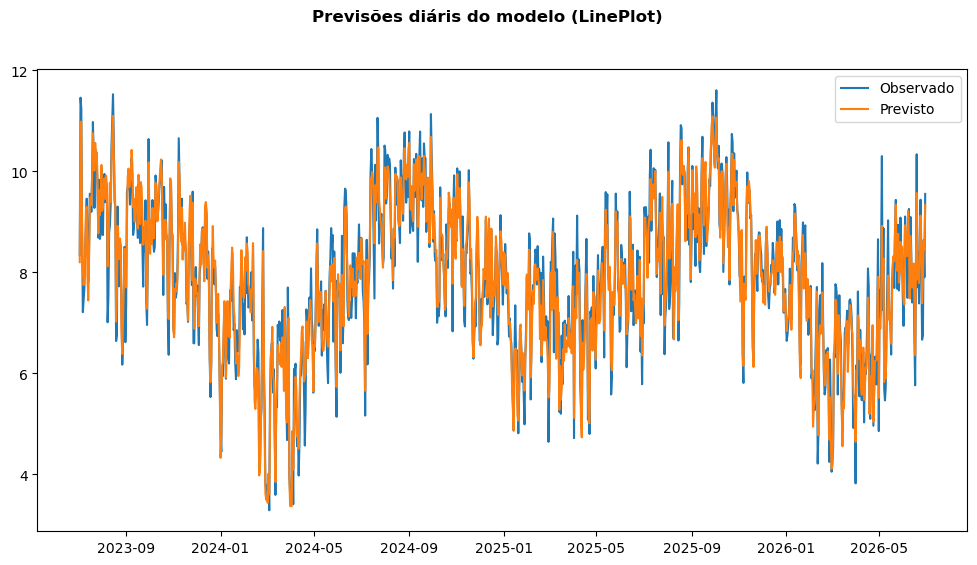

In [7]:
# Lineplot

fig, ax = plt.subplots(figsize=(12, 6))

fig.suptitle("Previsões diáris do modelo (LinePlot)", weight = "bold")

ax.plot(df_treino["TRUE"], label = "Observado")
ax.plot(df_treino["PRED"], label = "Previsto")

ax.legend()

# Olhando de maneira qualitativa parece bem coerente com a varíavel target a previsão

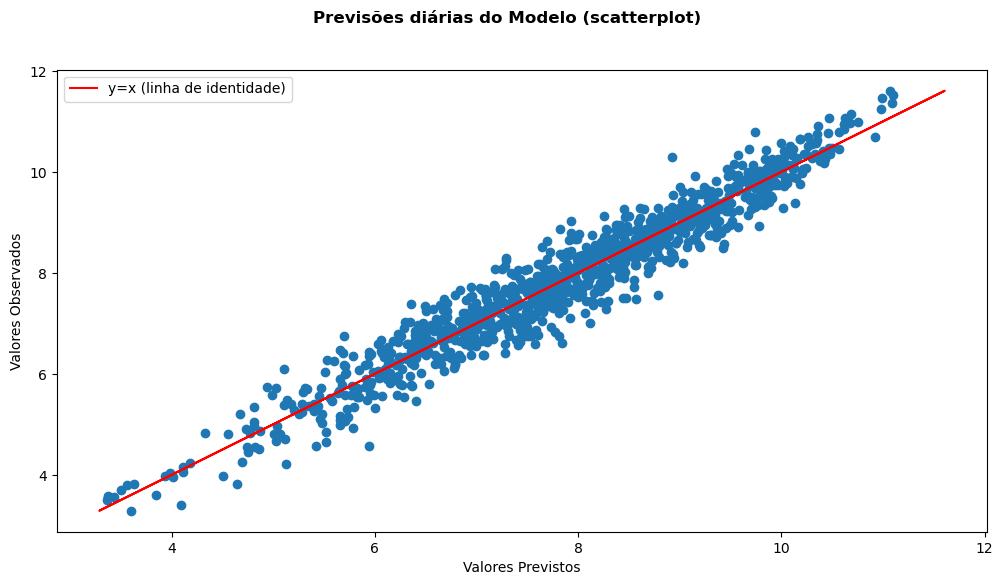

In [8]:
# Gráfico de Dispersão(Scatter Plot): 

fig, ax = plt.subplots(figsize=(12,6))

fig.suptitle("Previsões diárias do Modelo (scatterplot)", weight = "bold")

ax.scatter(x=df_treino["PRED"], y=df_treino["TRUE"])

ax.plot(df_treino["TRUE"], df_treino["TRUE"], color = "red", label="y=x (linha de identidade)")

ax.set_ylabel("Valores Observados")
ax.set_xlabel("Valores Previstos")

ax.legend() 


In [9]:
# AVALIAÇÃO QUANTITATIVA ( R², MAPE, BIAS): 

r2_01 = r2_score(y_true=df_treino["TRUE"], y_pred=df_treino["PRED"])
print(f"---R²: {r2_01:.3f}") #MUITO PERTO DE 1.0

mape_01 = mean_absolute_percentage_error(y_true=df_treino["TRUE"], y_pred=df_treino["PRED"])*100
print(f"-- MAPE: {mape_01:.3f}") # 4.08% DE ERRO

bias_01 = (df_treino["PRED"] - df_treino["TRUE"]).mean() #bias negativo não tem basicamente
print(f"-- BIAS: {bias_01:.3f}")



---R²: 0.933
-- MAPE: 4.089
-- BIAS: -0.002


# VISUALIZANDO OUTROS MODELOS: 

## PRED_2 

In [16]:
# PRED_2: 

df_treino2  = df[["PRED_2", "TRUE"]]

# Correto
df_treino.columns = ["PRED_2", "TRUE"]

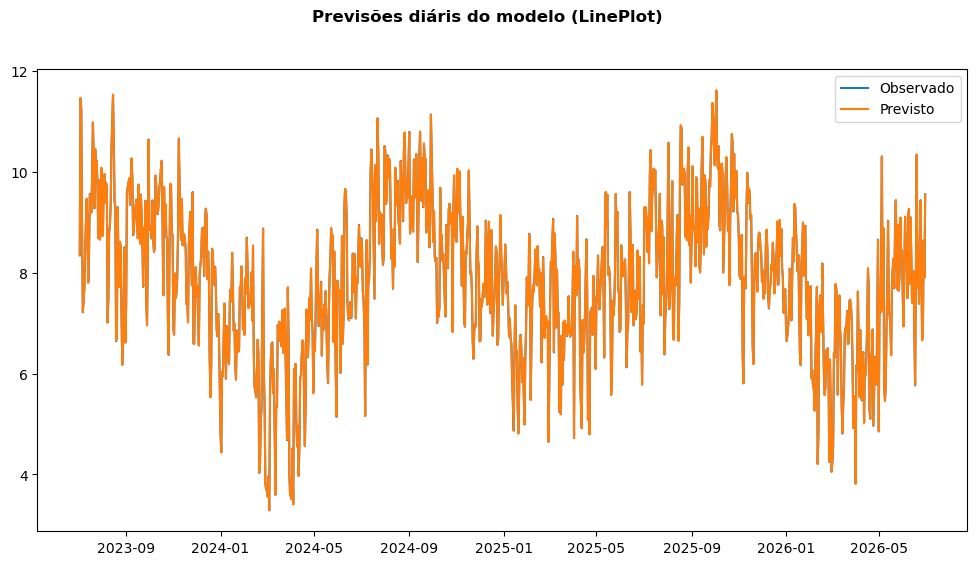

In [17]:
# Lineplot

fig, ax = plt.subplots(figsize=(12, 6))

fig.suptitle("Previsões diáris do modelo (LinePlot)", weight = "bold")

ax.plot(df_treino2["TRUE"], label = "Observado")
ax.plot(df_treino2["PRED_2"], label = "Previsto")

ax.legend()

# Olhando de maneira qualitativa parece bem coerente com a varíavel target a previsão

--> ACIMA TEMOS UM CLARO OVERFITTING DO PRED_2 

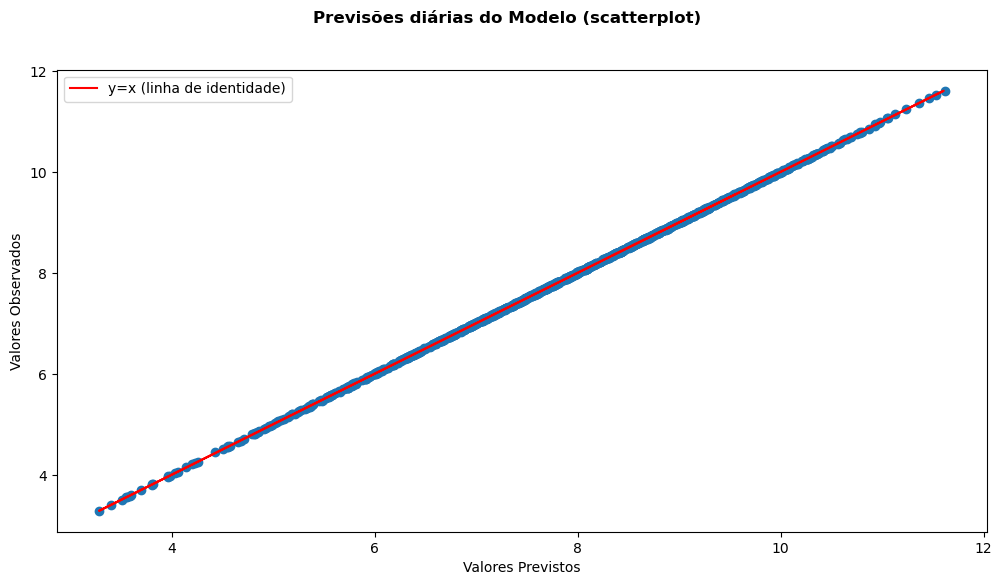

In [19]:
# Gráfico de Dispersão(Scatter Plot): 

fig, ax = plt.subplots(figsize=(12,6))

fig.suptitle("Previsões diárias do Modelo (scatterplot)", weight = "bold")

ax.scatter(x=df_treino2["PRED_2"], y=df_treino["TRUE"])

ax.plot(df_treino2["TRUE"], df_treino2["TRUE"], color = "red", label="y=x (linha de identidade)")

ax.set_ylabel("Valores Observados")
ax.set_xlabel("Valores Previstos")

ax.legend() 


--> MAIS UMA COMPROVAÇÃO DE OVERFITITNG DO PRED_2

In [22]:
# AVALIAÇÃO QUANTITATIVA ( R², MAPE, BIAS): 

r2_01 = r2_score(y_true=df_treino2["TRUE"], y_pred=df_treino2["PRED_2"])
print(f"---R²: {r2_01:.3f}") #MUITO PERTO DE 1.0

mape_01 = mean_absolute_percentage_error(y_true=df_treino2["TRUE"], y_pred=df_treino2["PRED_2"])*100
print(f"-- MAPE: {mape_01:.3f}") # 4.08% DE ERRO

bias_01 = (df_treino2["PRED_2"] - df_treino2["TRUE"]).mean() #bias negativo não tem basicamente
print(f"-- BIAS: {bias_01:.3f}")

---R²: 1.000
-- MAPE: 0.092
-- BIAS: -0.000


## PRED_3

In [30]:
# PRED_3: 

df_treino3  = df[["PRED_3", "TRUE"]]

# Correto
df_treino.columns = ["PRED_3", "TRUE"]

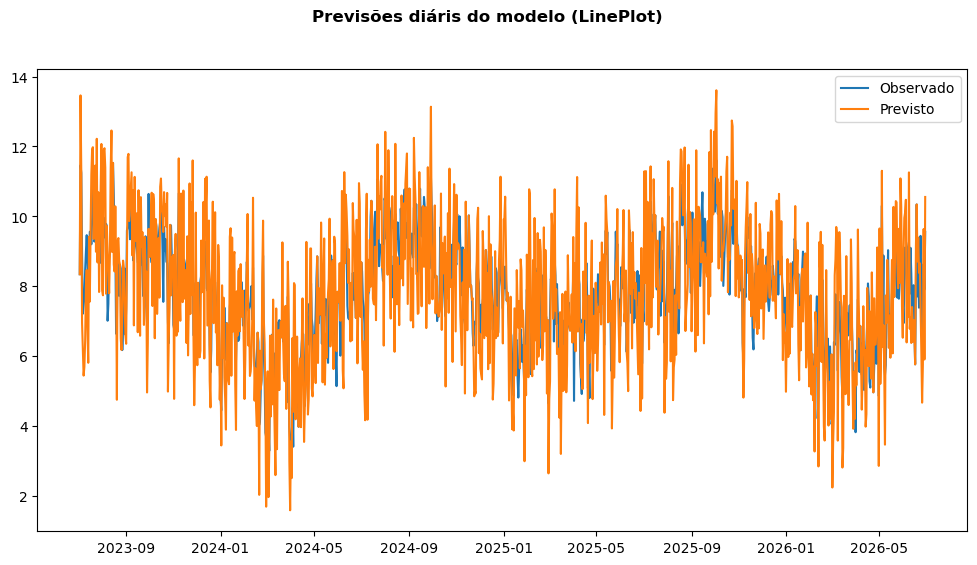

In [31]:
# Lineplot

fig, ax = plt.subplots(figsize=(12, 6))

fig.suptitle("Previsões diáris do modelo (LinePlot)", weight = "bold")

ax.plot(df_treino3["TRUE"], label = "Observado")
ax.plot(df_treino3["PRED_3"], label = "Previsto")

ax.legend()

# Olhando de maneira qualitativa parece bem coerente com a varíavel target a previsão

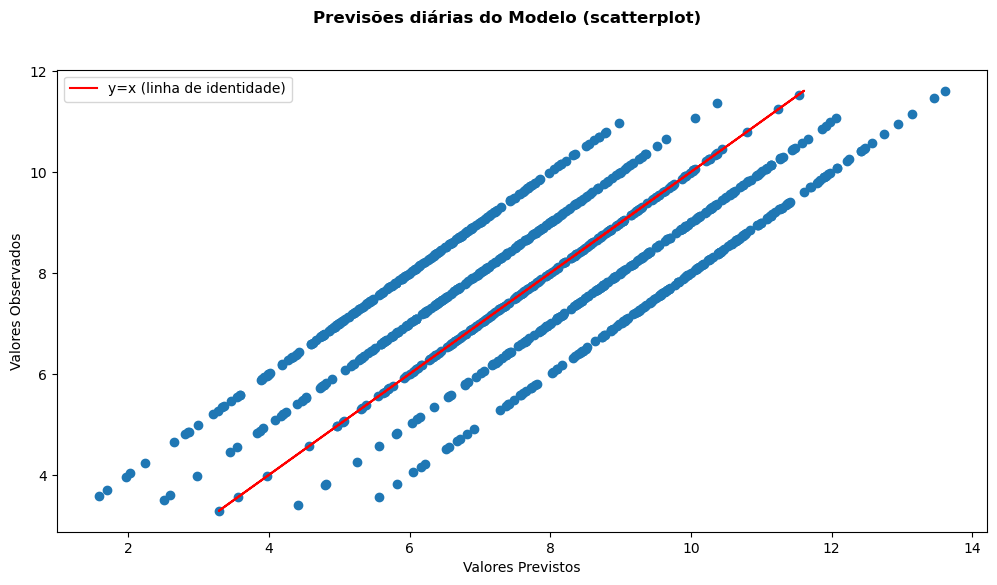

In [32]:
# Gráfico de Dispersão(Scatter Plot): 

fig, ax = plt.subplots(figsize=(12,6))

fig.suptitle("Previsões diárias do Modelo (scatterplot)", weight = "bold")

ax.scatter(x=df_treino3["PRED_3"], y=df_treino3["TRUE"])

ax.plot(df_treino3["TRUE"], df_treino3["TRUE"], color = "red", label="y=x (linha de identidade)")

ax.set_ylabel("Valores Observados")
ax.set_xlabel("Valores Previstos")

ax.legend() 


--> ACIMA TEMOS UM CLARO UNDERFITTING 

In [33]:
# AVALIAÇÃO QUANTITATIVA ( R², MAPE, BIAS): 

r2_01 = r2_score(y_true=df_treino3["TRUE"], y_pred=df_treino3["PRED_3"])
print(f"---R²: {r2_01:.3f}") #MUITO PERTO DE 1.0

mape_01 = mean_absolute_percentage_error(y_true=df_treino3["TRUE"], y_pred=df_treino3["PRED_3"])*100
print(f"-- MAPE: {mape_01:.3f}") # 4.08% DE ERRO

bias_01 = (df_treino2["PRED_3"] - df_treino2["TRUE"]).mean() #bias negativo não tem basicamente
print(f"-- BIAS: {bias_01:.3f}")

---R²: 0.111
-- MAPE: 15.683
-- BIAS: -0.048


## PRED_4

In [35]:
# PRED_4: 

df_treino4  = df[["PRED_4", "TRUE"]]

# Correto
df_treino.columns = ["PRED_4", "TRUE"]

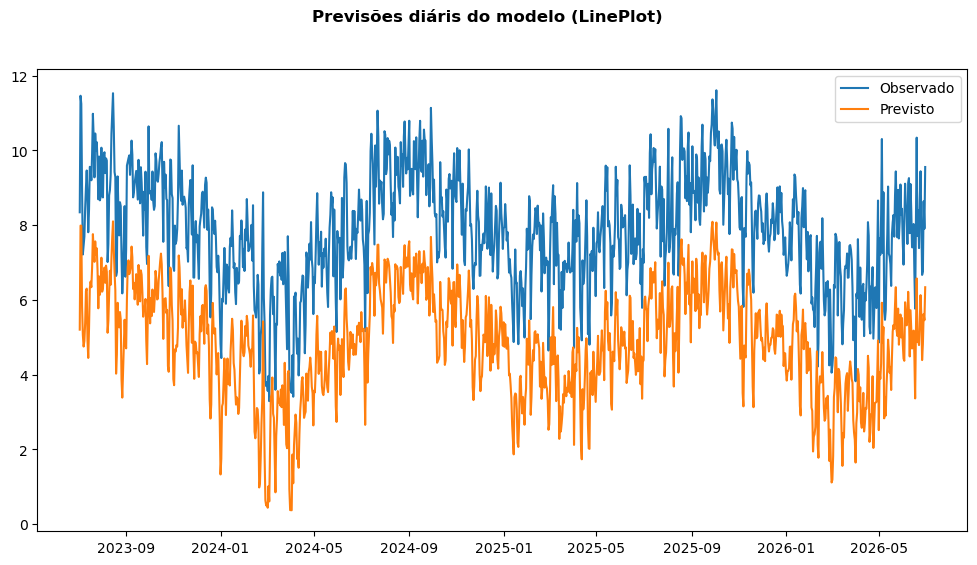

In [36]:
# Lineplot

fig, ax = plt.subplots(figsize=(12, 6))

fig.suptitle("Previsões diáris do modelo (LinePlot)", weight = "bold")

ax.plot(df_treino4["TRUE"], label = "Observado")
ax.plot(df_treino4["PRED_4"], label = "Previsto")

ax.legend()

# Olhando de maneira qualitativa parece bem coerente com a varíavel target a previsão

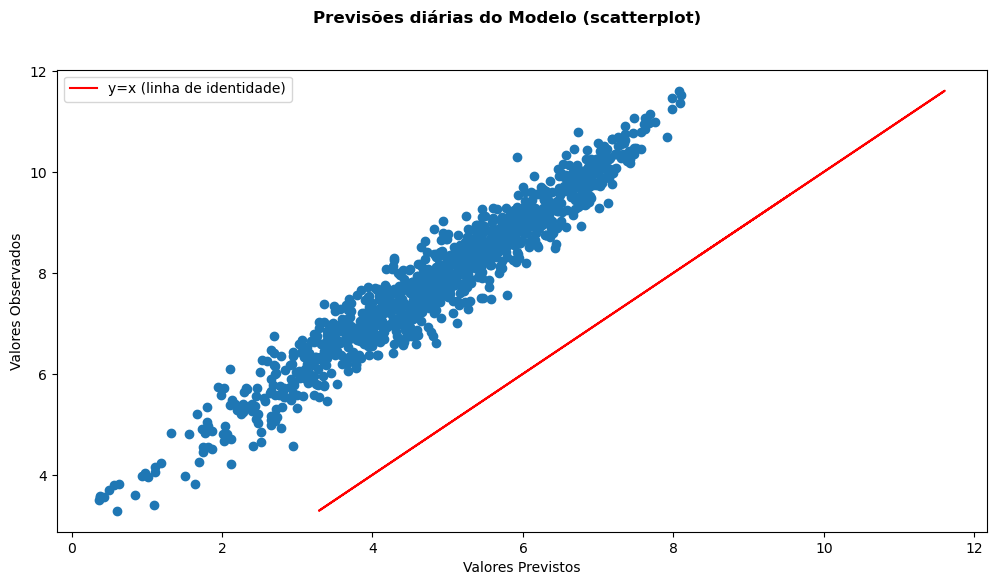

In [38]:
# Gráfico de Dispersão(Scatter Plot): 

fig, ax = plt.subplots(figsize=(12,6))

fig.suptitle("Previsões diárias do Modelo (scatterplot)", weight = "bold")

ax.scatter(x=df_treino4["PRED_4"], y=df_treino4["TRUE"])

ax.plot(df_treino4["TRUE"], df_treino4["TRUE"], color = "red", label="y=x (linha de identidade)")

ax.set_ylabel("Valores Observados")
ax.set_xlabel("Valores Previstos")

ax.legend() 

--> ACIMA TEMOS UM FORTE INDÍCIO DE BIAS:  